# Example 2.5 — Scaffold → target landscape (imatinib core)

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:24Z
- **Contents:** 1 exchange · 3 tool calls · 1 figure · 1 code cell

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/`, the figures in `figures/` and the analysis code the notebook imports (`nb_2_5_scaffold_target_landscape_notebook_code_1.py`). With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/2.5-scaffold-target-landscape-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 2.5-scaffold-target-landscape-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 2.5-scaffold-target-landscape-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/2.5-scaffold-target-landscape-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 2.5-scaffold-target-landscape-notebook-rerun.ipynb 2.5-scaffold-target-landscape-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Which targets have the most compounds containing the 2-anilino-4-(3-pyridyl)pyrimidine core of imatinib?

In [ ]:
# Call 1 · substructure_search · ran 2026-11-24 04:55:24 UTC
await replay.call(1, 'substructure_search', {'query': 'c1ccc(Nc2nccc(-c3cccnc3)n2)cc1', 'count_only': True},
                  sha256='bd808d64938931c9b65154c476b1988ff3c7c2c3c4862eb90bb9679758345ec1')

**Call 1** · `substructure_search` · recorded result · sha256 `bd808d649389…`

| name | smiles |
| --- | --- |
| query | c1ccc(Nc2nccc(-c3cccnc3)n2)cc1 |

```json
{
  "query": {
    "input": "c1ccc(Nc2nccc(-c3cccnc3)n2)cc1",
    "interpreted_as": "smiles",
    "canonical": "c1ccc(Nc2nccc(-c3cccnc3)n2)cc1"
  },
  "n_matching_compounds": 460,
  "compounds_searched": 1466457,
  "compounds_indexed": 1466457
}
```


In [ ]:
# Call 2 · substructure_search · ran 2026-11-24 04:55:24 UTC
arguments = {
    'query': 'c1ccc(Nc2nccc(-c3cccnc3)n2)cc1',
    'summarize_by_target': True,
    'max_value_nm': 10000,
    'limit': 500,
}
await replay.call(2, 'substructure_search', arguments,
                  sha256='6c05c862a2ded288271d47c6831e15078e9c6d302104f4c995d47ab3749c1c45')

**Call 2** · `substructure_search` · recorded result · sha256 `6c05c862a2de…`

| name | smiles |
| --- | --- |
| query | c1ccc(Nc2nccc(-c3cccnc3)n2)cc1 |

```json
{
  "query": {
    "input": "c1ccc(Nc2nccc(-c3cccnc3)n2)cc1",
    "interpreted_as": "smiles",
    "canonical": "c1ccc(Nc2nccc(-c3cccnc3)n2)cc1"
  },
  "n_matching_compounds": 460,
  "n_targets": 170,
  "n_compounds_measured": 394,
  "compounds_searched": 1466457,
  "search_set_size": 1466457
}
```

_170 rows_

| target_kind | target_id | target_name | uniprot_raw | organism | n_compounds | n_measurements | affinity_types | best_p_affinity |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 5221 | Tyrosine-protein kinase ABL1 | P00519 | Homo sapiens | 134 | 331 | EC50, IC50, Kd, Ki | 9.06 |
| polymer | 359 | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens | 120 | 217 | EC50, IC50, Kd, Ki | 8.7 |
| complex | 261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  | 69 | 130 | EC50, IC50, Ki | 9.48 |
| polymer | 50001306 | Tyrosine-protein kinase ABL2 | P42684 | Homo sapiens | 65 | 93 | IC50, Kd | 8 |
| polymer | 520 | Epidermal growth factor receptor | P00533 | Homo sapiens | 52 | 61 | IC50, Kd | 9.96 |
| polymer | 60 | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens | 50 | 56 | IC50 | 9.3 |
| polymer | 5778 | Platelet-derived growth factor receptor alpha | P16234 | Homo sapiens | 24 | 46 | EC50, IC50, Kd, Ki | 9.14 |
| polymer | 692 | Vascular endothelial growth factor receptor 2 | P35968 | Homo sapiens | 22 | 23 | IC50 | 7.8 |
| polymer | 5926 | Breakpoint cluster region protein \[1-693\] | P11274\[1-693\] | Homo sapiens | 21 | 21 | IC50 | 8 |
| polymer | 575 | Platelet-derived growth factor receptor beta | P09619 | Homo sapiens | 20 | 36 | IC50, Kd, Ki | 8.7 |
| polymer | 6797 | Serine/threonine-protein kinase TBK1 | Q9UHD2 | Homo sapiens | 19 | 19 | IC50 | 7.82 |
| polymer | 3207 | Inhibitor of nuclear factor kappa-B kinase subunit epsilon | Q14164 | Homo sapiens | 18 | 18 | IC50 | 7.82 |
| complex | 50000008 | Platelet-derived growth factor receptor alpha/beta |  |  | 16 | 26 | IC50 | 8 |
| polymer | 759 | Tyrosine-protein kinase ZAP-70 | P43403 | Homo sapiens | 14 | 14 | IC50, Ki | 8.1 |
| polymer | 1653 | Mitogen-activated protein kinase 10 | P53779 | Homo sapiens | 12 | 36 | IC50, Kd | 9.3 |
| polymer | 1358 | Receptor-type tyrosine-protein kinase FLT3 | P36888 | Homo sapiens | 11 | 16 | IC50, Kd, Ki | 8.1 |
| polymer | 599 | Protein kinase C alpha type | P17252 | Homo sapiens | 11 | 13 | IC50 | 6.49 |
| polymer | 13 | Proto-oncogene tyrosine-protein kinase Src | P12931 | Homo sapiens | 10 | 12 | IC50, Kd | 5.87 |
| polymer | 1663 | Mitogen-activated protein kinase 9 | P45984 | Homo sapiens | 9 | 26 | IC50, Kd | 9.15 |
| polymer | 1662 | Mitogen-activated protein kinase 8 | P45983 | Homo sapiens | 9 | 29 | IC50, Kd | 9 |
| complex | 50000208 | Tyrosine-protein kinase ABL1/ABL2 |  |  | 8 | 8 | IC50 | 7.4 |
| complex | 113 | Cyclin-T1/Cyclin-dependent kinase 9 |  |  | 7 | 8 | IC50 | 9 |
| polymer | 507 | Tyrosine-protein kinase Lck | P06239 | Homo sapiens | 7 | 17 | IC50, Kd, Ki | 7.4 |
| polymer | 5481 | Tyrosine-protein kinase Lyn | P07948 | Homo sapiens | 6 | 11 | IC50, Kd, Ki | 8.51 |
| polymer | 5709 | Discoidin domain-containing receptor 2 | Q16832 | Homo sapiens | 5 | 20 | IC50, Kd | 9.3 |
| complex | 97 | Cyclin-A2/Cyclin-dependent kinase 2 |  |  | 5 | 5 | IC50 | 7.74 |
| polymer | 4916 | Non-receptor tyrosine-protein kinase TYK2 | P29597 | Homo sapiens | 5 | 5 | IC50, Kd, Ki | 6.2 |
| polymer | 2700 | Serine/threonine-protein kinase PLK1 | P53350 | Homo sapiens | 5 | 5 | IC50 | 5.85 |
| polymer | 223 | Gag-Pol polyprotein \[489-587\] | P04585\[489-587\] | Human immunodeficiency virus 1 | 4 | 4 | Ki | 10.55 |
| polymer | 1193 | Carbonic anhydrase 2 | P00918 | Homo sapiens | 4 | 4 | Ki | 8.39 |
| polymer | 1233 | Carbonic anhydrase 9 | Q16790 | Homo sapiens | 4 | 4 | Ki | 8.09 |
| polymer | 50001198 | Breakpoint cluster region protein | Q6PAJ1 | Mus musculus | 4 | 6 | IC50 | 8 |
| polymer | 6885 | Bromodomain-containing protein 4 | O60885 | Homo sapiens | 4 | 4 | IC50 | 7.89 |
| polymer | 1363 | Carbonic anhydrase 12 | O43570 | Homo sapiens | 4 | 4 | Ki | 7.74 |
| polymer | 3881 | Mitogen-activated protein kinase 14 | Q16539 | Homo sapiens | 4 | 6 | EC50, IC50, Kd | 7.74 |
| polymer | 997 | Cyclin-dependent kinase 9 | P50750 | Homo sapiens | 4 | 4 | IC50 | 7.66 |
| polymer | 1192 | Carbonic anhydrase 1 | P00915 | Homo sapiens | 4 | 4 | Ki | 7.53 |
| polymer | 1967 | Histone deacetylase 1 | Q13547 | Homo sapiens | 4 | 5 | IC50 | 7.11 |
| complex | 50000112 | Protein kinase C (PKC) |  |  | 4 | 4 | IC50 | 6.82 |
| polymer | 796 | Cyclin-dependent kinase 2 | P24941 | Homo sapiens | 4 | 4 | IC50 | 6.77 |
| polymer | 2857 | Serine/threonine-protein kinase B-raf | P15056 | Homo sapiens | 4 | 7 | IC50, Kd | 6.74 |
| polymer | 3885 | Heme oxygenase 1 | P06762 | Rattus norvegicus | 4 | 4 | IC50 | 6.04 |
| polymer | 3993 | Epithelial discoidin domain-containing receptor 1 | Q08345 | Homo sapiens | 3 | 15 | IC50, Kd | 9.15 |
| polymer | 4453 | Tyrosine-protein kinase ABL1 \[1-999,Q252H\] | P00519\[1-999,Q252H\] | Homo sapiens | 3 | 4 | IC50 | 8.3 |
| polymer | 799 | Cyclin-dependent kinase 4 | P11802 | Homo sapiens | 3 | 3 | IC50 | 8.15 |
| polymer | 879 | Macrophage colony-stimulating factor 1 receptor | P07333 | Homo sapiens | 3 | 10 | IC50, Kd | 8 |
| polymer | 4981 | Aurora kinase B | Q96GD4 | Homo sapiens | 3 | 3 | IC50 | 7.92 |
| polymer | 1325 | Aurora kinase A | O14965 | Homo sapiens | 3 | 3 | IC50 | 7.82 |
| polymer | 763 | Tyrosine-protein kinase SYK | P43405 | Homo sapiens | 3 | 5 | IC50, Ki | 6.8 |
| polymer | 4918 | Tyrosine-protein kinase JAK2 | O60674 | Homo sapiens | 3 | 3 | IC50, Ki | 6.54 |
| polymer | 50003169 | Breakpoint cluster region protein | P11274 | Homo sapiens | 3 | 3 | IC50 | 6.24 |
| polymer | 7838 | Tyrosine-protein kinase ABL1 \[229-512\] | P00519\[229-512\] | Homo sapiens | 2 | 4 | Kd | 8.82 |
| polymer | 50000450 | 1-phosphatidylinositol 3-phosphate 5-kinase | Q9Y2I7 | Homo sapiens | 2 | 3 | Kd | 8.19 |
| polymer | 50001750 | Tyrosine-protein kinase ABL1 | P00520 | Mus musculus | 2 | 3 | IC50 | 8.07 |
| polymer | 50002885 | Mitogen-activated protein kinase kinase kinase 20 | Q9NYL2 | Homo sapiens | 2 | 4 | Kd | 7.96 |
| polymer | 7381 | Interleukin-1 receptor-associated kinase 1 | P51617 | Homo sapiens | 2 | 2 | IC50, Kd | 7.85 |
| polymer | 5588 | Corticotropin-releasing factor receptor 1 | P34998 | Homo sapiens | 2 | 2 | Ki | 7.6 |
| polymer | 50003030 | Ephrin type-A receptor 8 | P29322 | Homo sapiens | 2 | 5 | Kd | 7.43 |
| polymer | 5286 | Ribosyldihydronicotinamide dehydrogenase \[quinone\] | P16083 | Homo sapiens | 2 | 7 | IC50, Ki | 7.41 |
| polymer | 633 | Platelet-derived growth factor receptor beta | P05622 | Mus musculus | 2 | 2 | IC50 | 7.3 |
| polymer | 4919 | Tyrosine-protein kinase JAK3 | P52333 | Homo sapiens | 2 | 4 | IC50 | 7.26 |
| polymer | 50004142 | Carbonic anhydrase 15 | Q99N23 | Mus musculus | 2 | 2 | Ki | 7.11 |
| polymer | 2863 | Tyrosine-protein kinase FRK | P42685 | Homo sapiens | 2 | 6 | Kd, Ki | 7.07 |
| polymer | 1361 | Carbonic anhydrase 7 | P43166 | Homo sapiens | 2 | 2 | Ki | 7 |
| polymer | 4578 | Nuclear receptor subfamily 4 group A member 1 | P22736 | Homo sapiens | 2 | 3 | Kd | 6.92 |
| polymer | 1365 | Carbonic anhydrase 14 | Q9ULX7 | Homo sapiens | 2 | 2 | Ki | 6.65 |
| polymer | 6818 | Tyrosine-protein kinase Fgr | P09769 | Homo sapiens | 2 | 5 | Kd, Ki | 6.49 |
| polymer | 4451 | Serine/threonine-protein kinase TNNI3K | Q59H18 | Homo sapiens | 2 | 4 | Kd | 6.44 |
| polymer | 50004748 | Phosphatidylinositol 5-phosphate 4-kinase type-2 gamma | Q8TBX8 | Homo sapiens | 2 | 2 | Kd | 6.42 |
| polymer | 10154 | Carbonic anhydrase 6 | P23280 | Homo sapiens | 2 | 2 | Ki | 6.41 |
| polymer | 1247 | Carbonic anhydrase 4 | P22748 | Homo sapiens | 2 | 2 | Ki | 6.35 |
| polymer | 2920 | Carbonic anhydrase 3 | P07451 | Homo sapiens | 2 | 2 | Ki | 6.35 |
| polymer | 4026 | Broad substrate specificity ATP-binding cassette transporter ABCG2 | Q9UNQ0 | Homo sapiens | 2 | 7 | IC50 | 6.3 |
| polymer | 5620 | Tyrosine-protein kinase Blk | P51451 | Homo sapiens | 2 | 4 | Kd | 6.3 |
| polymer | 2939 | RAF proto-oncogene serine/threonine-protein kinase | P04049 | Homo sapiens | 2 | 5 | IC50, Kd | 5.96 |
| polymer | 5118 | Putative glycogen synthase kinase 3 alpha |  | Ustilago maydis (strain 521 / FGSC 9021) | 2 | 2 | IC50 | 5.94 |
| polymer | 8061 | Tyrosine-protein kinase Fyn | P06241 | Homo sapiens | 2 | 5 | Kd | 5.8 |
| polymer | 1003 | Glycogen synthase kinase-3 beta | P49841 | Homo sapiens | 2 | 2 | IC50 | 5.68 |
| polymer | 3913 | Dual specificity protein kinase CLK4 | Q9HAZ1 | Homo sapiens | 2 | 6 | Kd | 5.68 |
| polymer | 4897 | Dual specificity protein kinase CLK1 | P49759 | Homo sapiens | 2 | 5 | Kd | 5.68 |
| polymer | 1364 | Carbonic anhydrase 13 | Q9D6N1 | Mus musculus | 2 | 2 | Ki | 5.33 |
| polymer | 188 | Receptor tyrosine-protein kinase erbB-2 | P04626 | Homo sapiens | 1 | 1 | IC50 | 10.22 |
| polymer | 1385 | Tyrosine-protein kinase ABL1 \[201-500\] | P00519\[201-500\] | Homo sapiens | 1 | 1 | Kd | 8.7 |
| polymer | 1394 | Mast/stem cell growth factor receptor Kit \[N822K\] | P10721\[N822K\] | Homo sapiens | 1 | 1 | Kd | 8.52 |
| polymer | 50001579 | Ephrin type-B receptor 2 | P29323 | Homo sapiens | 1 | 2 | Kd, Ki | 8.4 |
| polymer | 1389 | Tyrosine-protein kinase ABL1 \[201-500,M351T\] | P00519\[201-500,M351T\] | Homo sapiens | 1 | 1 | Kd | 8 |
| polymer | 3995 | Discoidin domain-containing receptor 2 \[A642S\] | Q16832\[A642S\] | Homo sapiens | 1 | 1 | Kd | 7.82 |
| polymer | 49000507 | Ephrin type-B receptor 1 | P54762 | Homo sapiens | 1 | 2 | Kd, Ki | 7.82 |
| polymer | 1386 | Tyrosine-protein kinase ABL1 \[201-500,Q252H\] | P00519\[201-500,Q252H\] | Homo sapiens | 1 | 1 | Kd | 7.7 |
| polymer | 1390 | Tyrosine-protein kinase ABL1 \[201-500,F359V\] | P00519\[201-500,F359V\] | Homo sapiens | 1 | 1 | Kd | 7.7 |
| polymer | 1395 | Mast/stem cell growth factor receptor Kit \[V559D\] | P10721\[V559D\] | Homo sapiens | 1 | 1 | Kd | 7.7 |
| polymer | 2130 | Adenosine receptor A2a | P29274 | Homo sapiens | 1 | 1 | Ki | 7.57 |
| polymer | 4341 | Adenosine receptor A2b | P29275 | Homo sapiens | 1 | 1 | Ki | 7.52 |
| polymer | 8765 | Ephrin type-A receptor 2 \[596-900\] | P29317\[596-900\] | Homo sapiens | 1 | 2 | IC50, Kd | 7.48 |
| polymer | 2556 | Histone deacetylase 6 | Q9UBN7 | Homo sapiens | 1 | 1 | IC50 | 7.44 |
| polymer | 4481 | Mitogen-activated protein kinase 11 | Q15759 | Homo sapiens | 1 | 1 | Kd | 7.44 |
| polymer | 5496 | Ephrin type-B receptor 4 | P54760 | Homo sapiens | 1 | 2 | Kd, Ki | 7.43 |
| polymer | 1387 | Tyrosine-protein kinase ABL1 \[201-500,Y253F\] | P00519\[201-500,Y253F\] | Homo sapiens | 1 | 1 | Kd | 7.4 |
| polymer | 50006151 | Multidrug and toxin extrusion protein 1 | Q96FL8 | Homo sapiens | 1 | 3 | IC50 | 7.4 |
| polymer | 243 | Epidermal growth factor receptor \[T790M\] | P00533\[T790M\] | Homo sapiens | 1 | 3 | IC50 | 7.26 |
| polymer | 1391 | Tyrosine-protein kinase ABL1 \[201-500,H396P\] | P00519\[201-500,H396P\] | Homo sapiens | 1 | 1 | Kd | 7.22 |
| polymer | 50004854 | Serine/threonine-protein kinase PknB | P9WI81 | Mycobacterium tuberculosis (strain ATCC 25618 / H37Rv) | 1 | 3 | IC50, Kd, Ki | 7.21 |
| complex | 200 | Phosphatidylinositol 4,5-bisphosphate 3-kinase catalytic subunit gamma isoform/Phosphoinositide 3-kinase regulatory subunit 5 |  |  | 1 | 1 | IC50 | 7.1 |
| polymer | 1388 | Tyrosine-protein kinase ABL1 \[201-500,E255K\] | P00519\[201-500,E255K\] | Homo sapiens | 1 | 1 | Kd | 7 |
| polymer | 5401 | Ephrin type-A receptor 3 | P29320 | Homo sapiens | 1 | 1 | Kd | 6.96 |
| complex | 50000562 | Tyrosine-protein kinase ABL1 \[T315I\]/Breakpoint cluster region protein |  |  | 1 | 1 | IC50 | 6.94 |
| polymer | 2132 | Potassium voltage-gated channel subfamily H member 2 | Q12809 | Homo sapiens | 1 | 3 | IC50 | 6.9 |
| polymer | 50001175 | Platelet-derived growth factor receptor beta | Q05030 | Rattus norvegicus | 1 | 1 | IC50 | 6.79 |
| polymer | 50000594 | Dual specificity mitogen-activated protein kinase kinase 5 | Q13163 | Homo sapiens | 1 | 1 | Kd | 6.72 |
| polymer | 50003028 | Ephrin type-A receptor 2 | P29317 | Homo sapiens | 1 | 1 | Kd | 6.64 |
| polymer | 50006377 | Cyclin-K | O75909 | Homo sapiens | 1 | 1 | IC50 | 6.63 |
| complex | 112 | Cyclin-H/Cyclin-dependent kinase 7 |  |  | 1 | 1 | IC50 | 6.54 |
| polymer | 50003041 | Ephrin type-A receptor 4 | P54764 | Homo sapiens | 1 | 1 | Kd | 6.48 |
| polymer | 50006152 | Multidrug and toxin extrusion protein 2 | Q86VL8 | Homo sapiens | 1 | 2 | IC50 | 6.46 |
| polymer | 4465 | Tyrosine-protein kinase HCK | P08631 | Homo sapiens | 1 | 1 | Kd | 6.41 |
| polymer | 1744 | 3-phosphoinositide-dependent protein kinase 1 | O15530 | Homo sapiens | 1 | 1 | IC50 | 6.4 |
| polymer | 6476 | BDNF/NT-3 growth factors receptor | Q16620 | Homo sapiens | 1 | 2 | Kd, Ki | 6.31 |
| polymer | 50004569 | Ephrin type-B receptor 6 | O15197 | Homo sapiens | 1 | 1 | Kd | 6.3 |
| polymer | 5527 | Macrophage colony-stimulating factor 1 receptor | P09581 | Mus musculus | 1 | 1 | IC50 | 6.27 |
| polymer | 1846 | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 1 | 3 | IC50 | 6.26 |
| polymer | 5623 | Tyrosine-protein kinase ITK/TSK | Q08881 | Homo sapiens | 1 | 3 | IC50 | 6.26 |
| polymer | 2127 | Cytochrome P450 3A4 | P08684 | Homo sapiens | 1 | 1 | IC50 | 6.24 |
| polymer | 7531 | ATP-dependent translocase ABCB1 | P08183 | Homo sapiens | 1 | 2 | IC50 | 6.24 |
| polymer | 10230 | Ephrin type-A receptor 1 | P21709 | Homo sapiens | 1 | 1 | Kd | 6.23 |
| polymer | 6477 | NT-3 growth factor receptor | Q16288 | Homo sapiens | 1 | 1 | Kd | 6.22 |
| polymer | 50003066 | Ephrin type-A receptor 6 | Q9UF33 | Homo sapiens | 1 | 1 | Kd | 6.19 |
| polymer | 4366 | Calcium-dependent protein kinase 1 | P62343 | Plasmodium falciparum (isolate K1 / Thailand) | 1 | 1 | Kd | 6.1 |
| polymer | 5974 | Proto-oncogene tyrosine-protein kinase receptor Ret | P07949 | Homo sapiens | 1 | 2 | Kd | 6.06 |
| polymer | 50004052 | Mitogen-activated protein kinase kinase kinase kinase 1 | Q92918 | Homo sapiens | 1 | 1 | Kd | 6.05 |
| polymer | 5237 | Serine/threonine-protein kinase MRCK beta | Q9Y5S2 | Homo sapiens | 1 | 1 | Kd | 6.04 |
| polymer | 50004557 | Homeodomain-interacting protein kinase 4 | Q8NE63 | Homo sapiens | 1 | 1 | Kd | 6.02 |
| polymer | 808 | Angiopoietin-1 receptor | Q02763 | Homo sapiens | 1 | 2 | Kd, Ki | 6 |
| polymer | 5427 | Ephrin type-B receptor 3 | P54753 | Homo sapiens | 1 | 1 | Kd | 6 |
| polymer | 50002896 | Cyclin-G-associated kinase | O14976 | Homo sapiens | 1 | 4 | Kd | 6 |
| polymer | 50003646 | Tyrosine-protein kinase receptor Tie-1 | P35590 | Homo sapiens | 1 | 1 | Kd | 6 |
| polymer | 5424 | Tyrosine-protein kinase Yes | P07947 | Homo sapiens | 1 | 1 | Kd | 5.96 |
| polymer | 5224 | Tyrosine-protein kinase ABL1 \[1-999,E255K\] | P00519\[1-999,E255K\] | Homo sapiens | 1 | 1 | IC50 | 5.92 |
| polymer | 7795 | Ferrochelatase, mitochondrial \[R115L\] | P22830\[R115L\] | Homo sapiens | 1 | 1 | Kd | 5.77 |
| polymer | 50004246 | Serine/threonine-protein kinase TAO3 | Q9H2K8 | Homo sapiens | 1 | 1 | Kd | 5.77 |
| polymer | 7407 | Maternal embryonic leucine zipper kinase | Q14680 | Homo sapiens | 1 | 3 | Kd | 5.72 |
| polymer | 50003039 | Ephrin type-A receptor 5 | P54756 | Homo sapiens | 1 | 1 | Kd | 5.72 |
| polymer | 50003023 | Serine/threonine-protein kinase PLK4 | O00444 | Homo sapiens | 1 | 5 | Kd, Ki | 5.66 |
| polymer | 2869 | Tyrosine-protein kinase CSK | P41240 | Homo sapiens | 1 | 1 | Kd | 5.62 |
| polymer | 3933 | Proto-oncogene tyrosine-protein kinase Src | P00523 | Gallus gallus | 1 | 1 | IC50 | 5.56 |
| polymer | 4493 | Serine/threonine-protein kinase 17A | Q9UEE5 | Homo sapiens | 1 | 3 | Kd | 5.55 |
| polymer | 1051 | Mast/stem cell growth factor receptor Kit \[V559D,T670I\] | P10721\[V559D,T670I\] | Homo sapiens | 1 | 1 | Kd | 5.52 |
| polymer | 50003766 | Lysine--tRNA ligase | Q15046 | Homo sapiens | 1 | 1 | Kd | 5.5 |
| polymer | 5758 | Leucine-rich repeat serine/threonine-protein kinase 2 | Q5S007 | Homo sapiens | 1 | 2 | IC50 | 5.48 |
| polymer | 858 | Insulin receptor | P06213 | Homo sapiens | 1 | 1 | Ki | 5.39 |
| polymer | 50006127 | Solute carrier family 22 member 2 | O15244 | Homo sapiens | 1 | 1 | IC50 | 5.38 |
| polymer | 3911 | Dual specificity protein kinase CLK1 \[R432A\] | P49759\[R432A\] | Homo sapiens | 1 | 1 | Kd | 5.35 |
| complex | 50000101 | Voltage-gated L-type calcium channel |  |  | 1 | 1 | IC50 | 5.33 |
| polymer | 50003871 | Serine/threonine-protein kinase TAO1 | Q7L7X3 | Homo sapiens | 1 | 1 | Kd | 5.33 |
| polymer | 2712 | Cytoplasmic tyrosine-protein kinase BMX | P51813 | Homo sapiens | 1 | 1 | Ki | 5.32 |
| polymer | 1228 | Carbonic anhydrase 5A, mitochondrial | P35218 | Homo sapiens | 1 | 1 | Ki | 5.26 |
| polymer | 3735 | Cyclin-dependent kinase 19 | Q9BWU1 | Homo sapiens | 1 | 3 | Kd | 5.26 |
| complex | 50000561 | cAMP-dependent protein kinase catalytic subunit alpha/beta/gamma |  |  | 1 | 1 | IC50 | 5.22 |
| polymer | 1392 | Tyrosine-protein kinase ABL1 \[201-500,T315I\] | P00519\[201-500,T315I\] | Homo sapiens | 1 | 1 | Kd | 5.22 |
| polymer | 2333 | Sphingosine 1-phosphate receptor 2 | O95136 | Homo sapiens | 1 | 1 | Kd | 5.22 |
| polymer | 5399 | Serine/threonine-protein kinase 10 | O94804 | Homo sapiens | 1 | 1 | Kd | 5.17 |
| polymer | 4906 | Hepatocyte growth factor receptor | P08581 | Homo sapiens | 1 | 1 | Ki | 5.15 |
| polymer | 856 | Fibroblast growth factor receptor 2 | P21802 | Homo sapiens | 1 | 1 | Ki | 5.14 |
| polymer | 694 | Fibroblast growth factor receptor 1 | P11362 | Homo sapiens | 1 | 1 | Ki | 5.1 |
| polymer | 350 | Leucine-rich repeat serine/threonine-protein kinase 2 \[970-2527\] | Q5S007\[970-2527\] | Homo sapiens | 1 | 1 | IC50 | 5.08 |
| polymer | 49000990 | Ret proto-oncogene |  | Homo sapiens | 1 | 1 | Ki | 5.06 |
| polymer | 6655 | Macrophage-stimulating protein receptor | Q04912 | Homo sapiens | 1 | 1 | Ki | 5.05 |
| complex | 50000025 | Cyclin-A1/Cyclin-A2/Cyclin-dependent kinase 2 |  |  | 1 | 1 | IC50 | 5.03 |
| polymer | 4753 | Replicase polyprotein 1ab | P0C6X7 | Severe acute respiratory syndrome coronavirus | 1 | 1 | EC50 | 5.01 |
| polymer | 823 | Spike glycoprotein | P59594 | Severe acute respiratory syndrome coronavirus | 1 | 1 | EC50 | 5 |
| polymer | 7532 | Bile salt export pump | O95342 | Homo sapiens | 1 | 1 | IC50 | 5 |


In [ ]:
# Call 3 · substructure_search · ran 2026-11-24 04:55:24 UTC
await replay.call(3, 'substructure_search', {'query': 'c1ccc(Nc2nccc(-c3cccnc3)n2)cc1', 'target_id': 60, 'limit': 10},
                  sha256='a2fa95183e3ba9b74fec736a3858c43da1a3774973a5ff3a841c514e86be4190')

**Call 3** · `substructure_search` · recorded result · sha256 `a2fa95183e3b…`

| name | smiles |
| --- | --- |
| query | c1ccc(Nc2nccc(-c3cccnc3)n2)cc1 |

```json
{
  "query": {
    "input": "c1ccc(Nc2nccc(-c3cccnc3)n2)cc1",
    "interpreted_as": "smiles",
    "canonical": "c1ccc(Nc2nccc(-c3cccnc3)n2)cc1"
  },
  "n_matching_compounds": 51,
  "compounds_searched": 1276,
  "search_set_size": 1276
}
```

_10 rows, truncated at the limit_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements | smiles |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 829805 | IC50 | = | 0.5 | nM | 9.3 | 414541 | US10435400, Compound Z-54 | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Wild Type EGFR and Mutant EGFR Kinase Inhibition Test | US10435400-B2 |  | 2019 | 0.34 | 4.74 |  | 1 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)cc(Cl)c2c1 |
| 761710 | IC50 | = | 1 | nM | 9 | 380786 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-4-methoxy-5-(4-(1-methyl-1H-pyrrolo\[2,3-b\]pyridin-5-yl)-7H-pyrrolo\[2,3-d\]pyrimidin-2-ylamino)phenyl)acrylamide | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Inhibition Assay | US9890168-B2 |  | 2018 | 0.31 | 4.61 |  | 1 | C=CC(=O)Nc1cc(Nc2nc(-c3cnc4c(ccn4C)c3)c3cc\[nH\]c3n2)c(OC)cc1N(C)CCN(C)C |
| 829775 | IC50 | = | 1 | nM | 9 | 414525 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-4-methoxy-5-((4-(1-methyl-1H-pyrrolo\[2,3-b\]pyridin-5-yl)pyrimidin-2-yl)amino)phenyl)acrylamide | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Wild Type EGFR and Mutant EGFR Kinase Inhibition Test | US10435400-B2 |  | 2019 | 0.33 | 5.1 |  | 2 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 |
| 829875 | IC50 | = | 1 | nM | 9 | 414577 | US10435400, Compound Z-123 | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Wild Type EGFR and Mutant EGFR Kinase Inhibition Test | US10435400-B2 |  | 2019 | 0.32 | 4.3 |  | 1 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cnc2n(C)cc(Cl)c2c1 |
| 1094891 | IC50 | \< | 1 | nM | 9 | 517826 | N-(2-((2-(dimethylamino)ethyl)(methyl)amino)-5-((5-fluoro-4-(8-fluoro-3-isopropyl-2-m ethylimidazo\[1,2-a\]pyridine-6-yl)pyrimidin-2-yl)amino)-4-methoxyphenyl)acrylamide | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Kinase Inhibition Assay | US11111233-B2 |  | 2021 | 0.29 | 3.62 |  | 1 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cc(F)c2nc(C)c(C(C)C)n2c1 |
| 829777 | IC50 | = | 2 | nM | 8.7 | 414526 | US10435400, Compound Z-20 | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Wild Type EGFR and Mutant EGFR Kinase Inhibition Test | US10435400-B2 |  | 2019 | 0.31 | 5.41 |  | 1 | COc1cc(N(C)CCN(C)N)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cnc2n(C)ccc2c1 |
| 829791 | IC50 | = | 2 | nM | 8.7 | 414534 | US10435400, Compound Z-32 | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Wild Type EGFR and Mutant EGFR Kinase Inhibition Test | US10435400-B2 |  | 2019 | 0.3 | 4.59 |  | 1 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(C(C)=O)c(n1)-c1cnc2n(C)ccc2c1 |
| 829811 | IC50 | = | 2 | nM | 8.7 | 414544 | US10435400, Compound comparative | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Wild Type EGFR and Mutant EGFR Kinase Inhibition Test | US10435400-B2 |  | 2019 | 0.34 | 4.75 |  | 2 | COc1cc(N2CCC(CC2)N(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cccnc1 |
| 829849 | IC50 | = | 2 | nM | 8.7 | 414564 | US10435400, Compound Z-106 | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Wild Type EGFR and Mutant EGFR Kinase Inhibition Test | US10435400-B2 |  | 2019 | 0.33 | 5.14 |  | 1 | CNCCN(C)c1cc(OC)c(Nc2nccc(n2)-c2cnc3n(C)ccc3c2)cc1NC(=O)C=C |
| 829867 | IC50 | = | 2 | nM | 8.7 | 414573 | US10435400, Compound Z-117 | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Wild Type EGFR and Mutant EGFR Kinase Inhibition Test | US10435400-B2 |  | 2019 | 0.33 | 4.85 |  | 1 | COc1cc(OCCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 |


**Figure 1: Top 15 targets of compounds containing the imatinib core.** Number of compounds containing the 2-anilino-4-(3-pyridyl)pyrimidine substructure that bind each target at 10 µM or better. Orange: imatinib's clinical targets (ABL/BCR-ABL, KIT, PDGFR). Mutants, constructs and complexes are counted as separate targets. _(as recorded; running this cell draws it again)_

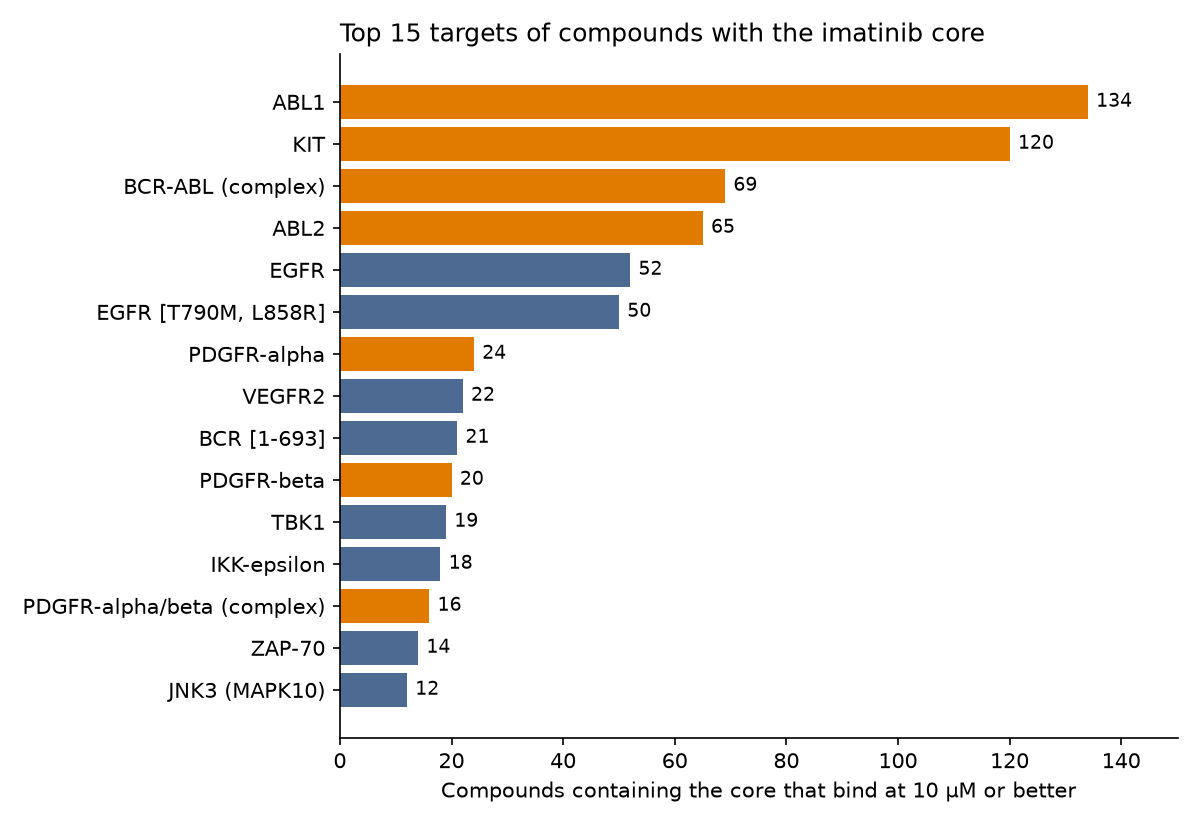

In [ ]:
# Code 1: Bar chart of the 15 targets with the most compounds containing the core
# The code is in nb_2_5_scaffold_target_landscape_notebook_code_1.py, next to this notebook (42 lines).
from nb_2_5_scaffold_target_landscape_notebook_code_1 import *

plot_top_targets(replay.result(2))

**🧠 Assistant**

**460 compounds** in BindingDB contain the 2-anilino-4-(3-pyridyl)pyrimidine core (c1ccc(Nc2nccc(-c3cccnc3)n2)cc1). **394** of them bind at least one target at 10 µM or better, and together they reach **170 targets**. The figure below shows the 15 targets with the most such compounds.

| Target | Compounds (≤ 10 µM) | Measurements | Best pAffinity |
| --- | --- | --- | --- |
| ABL1 | 134 | 331 | 9.06 |
| KIT | 120 | 217 | 8.7 |
| BCR-ABL (complex) | 69 | 130 | 9.48 |
| ABL2 | 65 | 93 | 8.0 |
| EGFR | 52 | 61 | 9.96 |
| EGFR [T790M, L858R] | 50 | 56 | 9.3 |
| PDGFR-alpha | 24 | 46 | 9.14 |
| VEGFR2 | 22 | 23 | 7.8 |
| BCR [1-693] | 21 | 21 | 8.0 |
| PDGFR-beta | 20 | 36 | 8.7 |

The top of the list is what you would expect for imatinib's chemotype: **ABL1, KIT, BCR-ABL and the PDGFRs**, imatinib's clinical targets. Further down are kinases the scaffold has been tuned towards in other projects: EGFR, VEGFR2, TBK1/IKK-epsilon, ZAP-70 and the JNKs (MAPK10).

The two **EGFR** entries are a surprise. Looking at the EGFR [T790M, L858R] hits (51 compounds contain the core on this target; 50 of them have a value at 10 µM or better) shows a different drug class. They are covalent EGFR inhibitors from patents (for example US10435400, IC50 0.5 nM) with an acrylamide warhead, in which the "3-pyridyl" ring is part of a fused pyrrolo[2,3-b]pyridine (an azaindole), or a similar fused bicycle in other patents:

| Compound | Mutant-EGFR IC50 | SMILES |
| --- | --- | --- |
| US10435400, Compound Z-54 | 0.5 nM | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)cc(Cl)c2c1 |
| US10435400 analogue (BDBM414525) | 1 nM | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)ccc2c1 |

**Lesson: summarize first, then look inside.** Listing 460 compounds one by one does not tell you much. summarize_by_target turns the same search into a profile of the scaffold: which targets, how many compounds, and how potent. Three things to keep in mind when you read it:

- **Counts follow research effort, not only biology.** ABL1 tops the list partly because most of these compounds were made in ABL projects.
- **Mutants, constructs and complexes are separate targets.** ABL1, BCR-ABL, the BCR fragment and EGFR [T790M, L858R] each get their own row. To get a per-gene view, add them up (or use find_ligands_for_target with include_variants).
- **A substructure can hide inside a bigger ring system.** The EGFR compounds match because a pyridine ring is part of their azaindole. Drill into surprising rows (here with target_id=60) before you draw conclusions.

Use max_value_nm (10,000 nM here) so that only compounds that actually bind are counted, not those measured and found inactive.

**How this was answered**

1. substructure_search with the core SMILES and count_only=true: 460 compounds.
2. substructure_search with summarize_by_target=true and max_value_nm=10000: 170 targets, ranked by number of binding compounds.
3. substructure_search with target_id=60 (EGFR [T790M, L858R]): the most potent matching compounds for that target.
4. The bar chart was drawn with matplotlib and added to the transcript with add_figure.

**Try next**

- "Build a clustered heat map of these compounds' affinities across their kinase targets" (Example 5.2, the kinase selectivity panel)
- "Find close analogues of imatinib": similarity instead of substructure (Example 2.2)

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 3 tool calls. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 2.5 — Scaffold → target landscape (imatinib core), 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```